<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 🗺️ Deep Research 知识地图：索引、原语速查、2026 现状、自测

**一句话定位**：deep research = **scoping → research（单 agent）→ supervision（多 agent）→ report** 四阶段；本课用 LangGraph 原语手搓全部四步并在每步做评估。这份是 6 份笔记的入口。

</div>

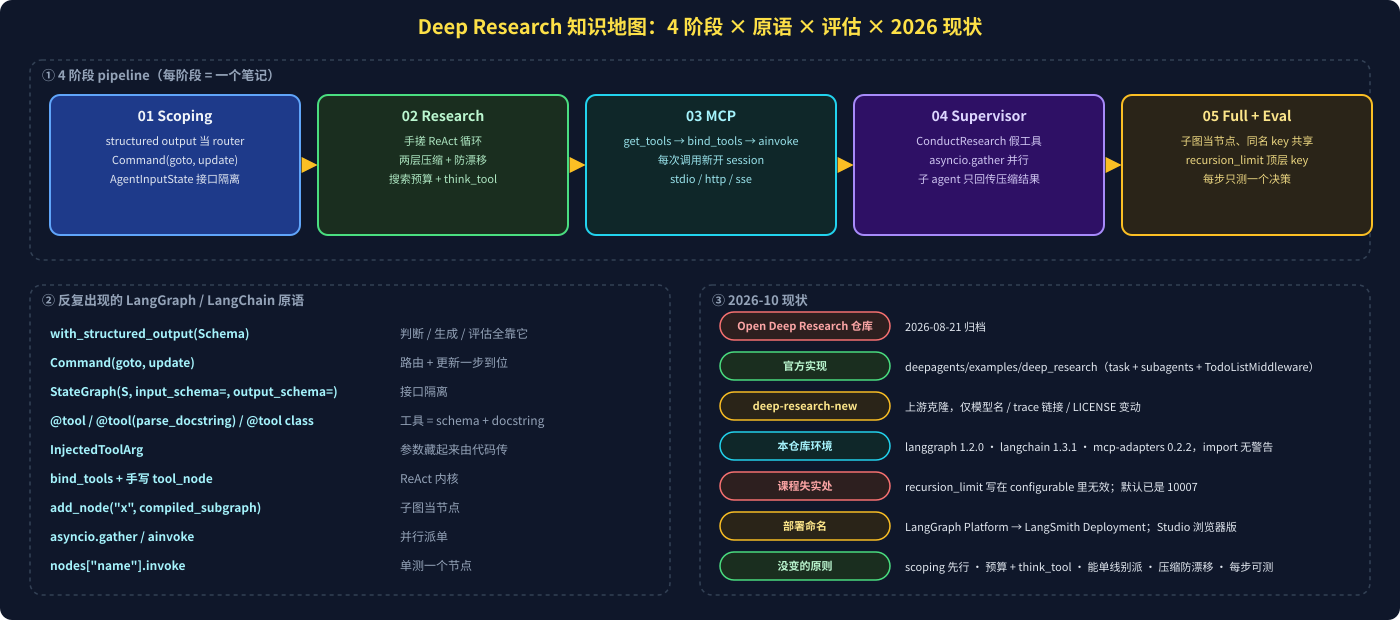

In [ ]:
from IPython.display import SVG
SVG(filename="assets/07_knowledge_map.svg")

### 📚 笔记索引

| # | 文件 | 一句话 | 主课 |
|---|---|---|---|
| 01 | `01_scoping_structured_output.ipynb` | structured output 当 router；`Command`；`AgentInputState` 接口隔离；两个 brief evaluator | 1 |
| 02 | `02_research_loop_context.ipynb` | 手搓 ReAct；`@tool(parse_docstring)` + `InjectedToolArg`；两层压缩 + 防漂移；搜索预算 + `think_tool`；停 / 继续 eval | 2 |
| 03 | `03_mcp_tools.ipynb` | `MultiServerMCPClient.get_tools`；只能 async；每次调用新开 session；transport 速查 | 3 |
| 04 | `04_supervisor_parallel.ipynb` | `ConductResearch` 假工具；两个节点互跳；`asyncio.gather`；context isolation；并行判断 eval | 4 |
| 05 | `05_full_pipeline_eval.ipynb` | 子图当节点；`recursion_limit` 真相；报告 prompt；全程评估点 | 5 |
| 06 | `06_from_scratch_vs_deepagents.ipynb` | 「新版」实为上游克隆；本课零件 ↔ deepagents 对照；时间线 | 全部 |
| 07 | 本文件 | 地图、原语速查、自测 | 全部 |

主课每份 `N_a` 里的 **🆕 2026-10** 格子记录了对应 cell 的过时点；`N_z_⭐️_本节精华` 末尾有指针。
同系列：新版 deep agents 课 `../../deep-agents-new/python/_学习索引.md`（deepagents 0.7 的 subagents / skills / memory / 部署）；旧 deep agents 课 `../../deep-agents-old/笔记/`；ambient agents 课 `../../ambiant-agents/笔记/`（HITL、评估、Store）。

### 🔧 原语速查

| 原语 | 本课在哪用 | 要点 |
|---|---|---|
| `model.with_structured_output(Schema)` | 澄清判断、写 brief、网页摘要、所有 judge | `Field(description=)` 是给模型的填写说明 |
| `Command(goto=..., update=...)` | 澄清节点、supervisor 两节点 | 路由 + 更新一步；注解 `-> Command[Literal[...]]` 才画得出边 |
| `StateGraph(S, input_schema=, output_schema=)` | 1_a / 2_a / 5_a | 对外收窄接口；0.5 起 `input=` 弃用 |
| `@tool(parse_docstring=True)` / `@tool class X(BaseModel)` | tavily_search / ConductResearch | docstring Args 段 → 参数描述；class 版无函数体 |
| `InjectedToolArg` | max_results / topic | 不进模型 schema；1.x 另有 `ToolRuntime` |
| `bind_tools` + 手写 `tool_node` | 2_a / 3_a | = `ToolNode` 的手搓版；MCP 工具要 `ainvoke` |
| `add_node("x", compiled_graph)` | 5_a | 子图当节点，同名 key 自动共享 |
| `asyncio.gather(*coros)` | 4_a | 并行子 agent |
| `graph.nodes["name"].invoke(...)` | 2_a / 4_a 的 eval | 单测一个节点 |
| `config={"configurable": {"thread_id"}, "recursion_limit": N}` | 5_a | `recursion_limit` 必须顶层；1.2 默认 10007 |

### 🧪 自测

1. `clarify_with_user` 怎么同时决定路由和给用户发问题？为什么多轮必须有 checkpointer？（01）
2. `AgentInputState` 只有 `messages`，`research_brief` 从哪来？（01）
3. 两个 brief evaluator 各测什么？为什么逐条 criteria 单独打分？（01）
4. 手搓 `tool_node` 和 `ToolNode` 差在哪两点？（02）
5. `InjectedToolArg` 的参数模型看得见吗？谁来传？（02）
6. 压缩节点末尾为什么要再加一条 HumanMessage？（02）
7. `think_tool` 什么都不做，它的价值是什么？（02）
8. MCP 工具为什么不能 `invoke`？每次 `ainvoke` 背后几趟网络往返？怎么复用？（03）
9. `"transport": "http"` 和 `"sse"` 分别对应什么端点？（03）
10. `ConductResearch` 没有函数体，模型「调用」它之后谁来执行？（04）
11. 子 agent 为什么用 `researcher_messages` 而不是 `messages`？（04）
12. supervisor 的三个退出条件？`research_iterations` 数的是什么？（04）
13. 子图当节点时，父子 state 怎么通信？（05）
14. `recursion_limit` 写在 `configurable` 里会怎样？1.2 默认值是多少？（05）
15. 「新版」`deep-research-new`（已删除的上游克隆）相对本仓库改了哪三样？哪些没改？（06）
16. 本课的 `ConductResearch` / `ResearchComplete` / `compress_research` 在 deepagents 里分别对应什么？（06）
17. 框架换了，哪五条原则没变？（06）

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：deep research = **scoping → research → supervision → report**；本课用 **structured output、Command、手搓 ReAct、asyncio.gather、子图当节点** 五个原语手搓全部四步，并**每步只测一个决策**。2026-10 官方实现换成 deepagents，但原则未变；`deep-research-new`（已删除）只是上游克隆。

</div>